In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from pathlib import Path

from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_squared_error
from sklearn.preprocessing import StandardScaler

In [3]:
data_path = Path("/Users/patrykksiazek/Desktop/Machine-Learning---Preliminary-Data-Analysis/")

In [4]:
grouped_train_logs = pd.read_csv(data_path / 'grouped_train_logs_advanced.csv').drop(columns={'Unnamed: 0'})
X_train_scores = pd.read_csv(data_path / 'X_train_scores.csv').drop(columns={'Unnamed: 0'})
X_test_scores = pd.read_csv(data_path / 'X_test_scores.csv').drop(columns={'Unnamed: 0'})

In [5]:
cols_to_drop = ['id', 'max_up_time', 'min_down_time', 'activity_len_per_essay_Nonproduction']

In [6]:
# Splitting the grouped_train_logs into train and test sets based on IDs
train_data = grouped_train_logs.merge(X_train_scores, on='id').drop(columns=cols_to_drop)
test_data = grouped_train_logs.merge(X_test_scores, on='id').drop(columns=cols_to_drop)

In [7]:
# Separating features and target variable
X_train = train_data.drop(['score'], axis=1)
y_train = train_data['score']
X_test = test_data.drop(['score'], axis=1)
y_test = test_data['score']

## XGBoost

In [8]:
import xgboost as xgb

In [9]:
from sklearn.model_selection import train_test_split

In [10]:
X_train, X_valid, y_train, y_valid = train_test_split(X_train, y_train, test_size=0.1, random_state=42)

In [11]:
dtrain = xgb.DMatrix(X_train, label=y_train)
dvalid = xgb.DMatrix(X_valid, label=y_valid) 
dtest = xgb.DMatrix(X_test, label=y_test) 

In [12]:
param = {'max_depth': 2}
evallist = [(dtrain, 'train'), (dvalid, 'eval')]

In [13]:
num_round = 20
bst = xgb.train(param, dtrain, num_round, evallist)

[0]	train-rmse:0.88589	eval-rmse:0.89176
[1]	train-rmse:0.80049	eval-rmse:0.82979
[2]	train-rmse:0.75022	eval-rmse:0.78979
[3]	train-rmse:0.72038	eval-rmse:0.76111
[4]	train-rmse:0.70309	eval-rmse:0.74676
[5]	train-rmse:0.69120	eval-rmse:0.73584
[6]	train-rmse:0.68206	eval-rmse:0.73271
[7]	train-rmse:0.67427	eval-rmse:0.72883
[8]	train-rmse:0.66876	eval-rmse:0.72660
[9]	train-rmse:0.66359	eval-rmse:0.71835
[10]	train-rmse:0.65870	eval-rmse:0.71861
[11]	train-rmse:0.65419	eval-rmse:0.72026
[12]	train-rmse:0.65034	eval-rmse:0.71467
[13]	train-rmse:0.64684	eval-rmse:0.70923
[14]	train-rmse:0.64349	eval-rmse:0.70799
[15]	train-rmse:0.64101	eval-rmse:0.70616
[16]	train-rmse:0.63868	eval-rmse:0.70580
[17]	train-rmse:0.63623	eval-rmse:0.70493
[18]	train-rmse:0.63453	eval-rmse:0.70390
[19]	train-rmse:0.63216	eval-rmse:0.70289


/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/xgboost/core.py:748: FutureWarning: Pass `evals` as keyword args.
  warnings.warn(msg, FutureWarning)


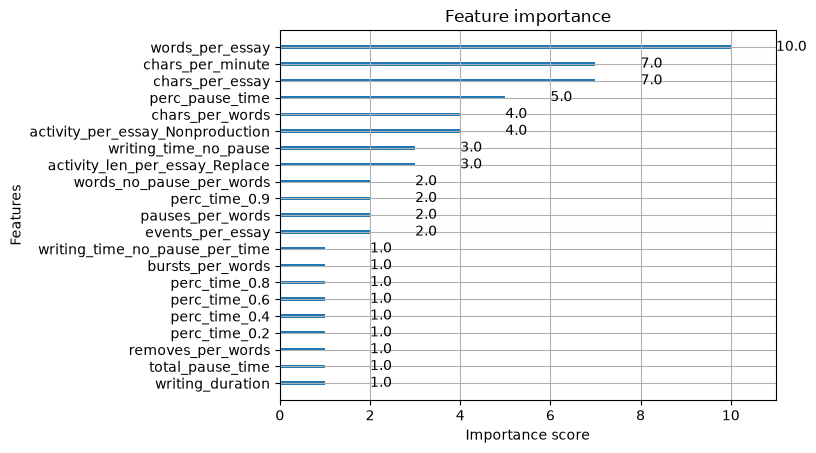

In [14]:
xgb.plot_importance(bst)
plt.show()

In [15]:
y_test_pred = bst.predict(dtest)

In [16]:
np.sqrt(mean_squared_error(y_test, y_test_pred))

0.6991169701581498

## Pewność Modelu

In [17]:
y_train_pred = bst.predict(dtrain)

In [18]:
train_rests = y_train_pred - y_train

In [19]:
train_rests

879     1.273265
100     0.110923
495     0.044784
1914   -0.390150
307     0.515910
          ...   
1130    0.545210
1294    0.539997
860    -0.487970
1459   -1.560021
1126    0.761107
Name: score, Length: 1778, dtype: float64

In [20]:
train_res = X_train.merge(train_rests, left_index=True, right_index=True)

In [21]:
train_res

,words_per_essay,events_per_essay,writing_duration,chars_per_essay,chars_per_minute,total_pauses,total_pause_time,perc_pause_time,pauses_per_words,removes_per_essay,...,perc_time_0.7,perc_time_0.8,perc_time_0.9,words_no_pause,writing_time_no_pause,group,bursts_per_words,words_no_pause_per_words,writing_time_no_pause_per_time,score
879,208,1989,1725113,1548,53.839951,96,1040544.0,0.603174,0.461538,382.0,...,0.659036,0.753399,0.786623,18.0,38602.0,97,0.466346,0.086538,0.022377,1.273265
100,776,5628,1865012,5050,162.465443,107,945018.0,0.506709,0.137887,467.0,...,0.711197,0.803114,0.905748,32.0,33724.0,108,0.139175,0.041237,0.018082,0.110923
495,497,5396,1740722,4188,144.353895,77,562507.0,0.323146,0.154930,1143.0,...,0.533528,0.599456,0.686678,43.0,67316.0,77,0.154930,0.086519,0.038671,0.044784
1914,230,3644,1775896,2574,86.964552,110,501481.0,0.282382,0.478261,746.0,...,0.404695,0.481026,0.661458,20.0,90850.0,111,0.482609,0.086957,0.051157,-0.390150
307,490,4025,1797438,3404,113.628398,142,998098.0,0.555289,0.289796,511.0,...,0.629216,0.711779,0.830345,21.0,30559.0,143,0.291837,0.042857,0.017001,0.515910
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1130,205,4152,1820371,3091,101.880331,85,499029.0,0.274136,0.414634,670.0,...,0.330160,0.384929,0.500025,17.0,123106.0,86,0.419512,0.082927,0.067627,0.545210
1294,203,1455,1833029,1279,41.865131,83,1375820.0,0.750572,0.408867,157.0,...,0.388209,0.421178,0.455677,12.0,37982.0,84,0.413793,0.059113,0.020721,0.539997
860,402,3146,1745669,2661,91.460638,98,1087781.0,0.623131,0.243781,259.0,...,0.387014,0.476520,0.762043,30.0,35482.0,98,0.243781,0.074627,0.020326,-0.487970
1459,204,4241,1743951,2765,95.128820,72,681013.0,0.390500,0.352941,1456.0,...,0.309089,0.353767,0.397056,14.0,227220.0,72,0.352941,0.068627,0.130290,-1.560021


In [23]:
train_res = train_res.merge(y_train, left_index=True, right_index=True)

In [25]:
train_res['y_train_pred'] = y_train_pred
train_res.rename(columns={'score_x': 'rest', 'score_y': 'y_train'}, inplace=True)

In [26]:
train_res

,words_per_essay,events_per_essay,writing_duration,chars_per_essay,chars_per_minute,total_pauses,total_pause_time,perc_pause_time,pauses_per_words,removes_per_essay,...,perc_time_0.9,words_no_pause,writing_time_no_pause,group,bursts_per_words,words_no_pause_per_words,writing_time_no_pause_per_time,rest,y_train,y_train_pred
879,208,1989,1725113,1548,53.839951,96,1040544.0,0.603174,0.461538,382.0,...,0.786623,18.0,38602.0,97,0.466346,0.086538,0.022377,1.273265,1.5,2.773265
100,776,5628,1865012,5050,162.465443,107,945018.0,0.506709,0.137887,467.0,...,0.905748,32.0,33724.0,108,0.139175,0.041237,0.018082,0.110923,5.0,5.110923
495,497,5396,1740722,4188,144.353895,77,562507.0,0.323146,0.154930,1143.0,...,0.686678,43.0,67316.0,77,0.154930,0.086519,0.038671,0.044784,4.5,4.544784
1914,230,3644,1775896,2574,86.964552,110,501481.0,0.282382,0.478261,746.0,...,0.661458,20.0,90850.0,111,0.482609,0.086957,0.051157,-0.390150,3.5,3.109850
307,490,4025,1797438,3404,113.628398,142,998098.0,0.555289,0.289796,511.0,...,0.830345,21.0,30559.0,143,0.291837,0.042857,0.017001,0.515910,4.0,4.515910
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1130,205,4152,1820371,3091,101.880331,85,499029.0,0.274136,0.414634,670.0,...,0.500025,17.0,123106.0,86,0.419512,0.082927,0.067627,0.545210,2.0,2.545210
1294,203,1455,1833029,1279,41.865131,83,1375820.0,0.750572,0.408867,157.0,...,0.455677,12.0,37982.0,84,0.413793,0.059113,0.020721,0.539997,1.5,2.039997
860,402,3146,1745669,2661,91.460638,98,1087781.0,0.623131,0.243781,259.0,...,0.762043,30.0,35482.0,98,0.243781,0.074627,0.020326,-0.487970,4.5,4.012030
1459,204,4241,1743951,2765,95.128820,72,681013.0,0.390500,0.352941,1456.0,...,0.397056,14.0,227220.0,72,0.352941,0.068627,0.130290,-1.560021,4.0,2.439979


In [28]:
train_res['rest'] = train_res['rest'].abs()

In [30]:
train_res

,words_per_essay,events_per_essay,writing_duration,chars_per_essay,chars_per_minute,total_pauses,total_pause_time,perc_pause_time,pauses_per_words,removes_per_essay,...,perc_time_0.9,words_no_pause,writing_time_no_pause,group,bursts_per_words,words_no_pause_per_words,writing_time_no_pause_per_time,rest,y_train,y_train_pred
879,208,1989,1725113,1548,53.839951,96,1040544.0,0.603174,0.461538,382.0,...,0.786623,18.0,38602.0,97,0.466346,0.086538,0.022377,1.273265,1.5,2.773265
100,776,5628,1865012,5050,162.465443,107,945018.0,0.506709,0.137887,467.0,...,0.905748,32.0,33724.0,108,0.139175,0.041237,0.018082,0.110923,5.0,5.110923
495,497,5396,1740722,4188,144.353895,77,562507.0,0.323146,0.154930,1143.0,...,0.686678,43.0,67316.0,77,0.154930,0.086519,0.038671,0.044784,4.5,4.544784
1914,230,3644,1775896,2574,86.964552,110,501481.0,0.282382,0.478261,746.0,...,0.661458,20.0,90850.0,111,0.482609,0.086957,0.051157,0.390150,3.5,3.109850
307,490,4025,1797438,3404,113.628398,142,998098.0,0.555289,0.289796,511.0,...,0.830345,21.0,30559.0,143,0.291837,0.042857,0.017001,0.515910,4.0,4.515910
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1130,205,4152,1820371,3091,101.880331,85,499029.0,0.274136,0.414634,670.0,...,0.500025,17.0,123106.0,86,0.419512,0.082927,0.067627,0.545210,2.0,2.545210
1294,203,1455,1833029,1279,41.865131,83,1375820.0,0.750572,0.408867,157.0,...,0.455677,12.0,37982.0,84,0.413793,0.059113,0.020721,0.539997,1.5,2.039997
860,402,3146,1745669,2661,91.460638,98,1087781.0,0.623131,0.243781,259.0,...,0.762043,30.0,35482.0,98,0.243781,0.074627,0.020326,0.487970,4.5,4.012030
1459,204,4241,1743951,2765,95.128820,72,681013.0,0.390500,0.352941,1456.0,...,0.397056,14.0,227220.0,72,0.352941,0.068627,0.130290,1.560021,4.0,2.439979


In [32]:
train_res.corr()['rest'].sort_values()

y_train                            -0.106944
perc_pause_time                    -0.079098
total_pause_time                   -0.067827
activity_per_essay_Paste           -0.044333
activity_len_per_essay_Replace     -0.043532
replaces_per_words                 -0.042415
chars_per_words                    -0.041351
removes_per_words                  -0.037663
pauses_per_words                   -0.035659
bursts_per_words                   -0.035340
removes_len_per_essay              -0.033119
total_pauses                       -0.026299
group                              -0.025487
activity_len_per_essay_Paste       -0.025115
activity_per_essay_Replace         -0.024927
perc_time_0.3                      -0.022691
words_no_pause_per_words           -0.020498
perc_time_0.4                      -0.016503
perc_time_0.2                      -0.010319
removes_per_essay                  -0.009174
y_train_pred                       -0.004646
perc_time_0.5                      -0.003671
writing_du

<Axes: >

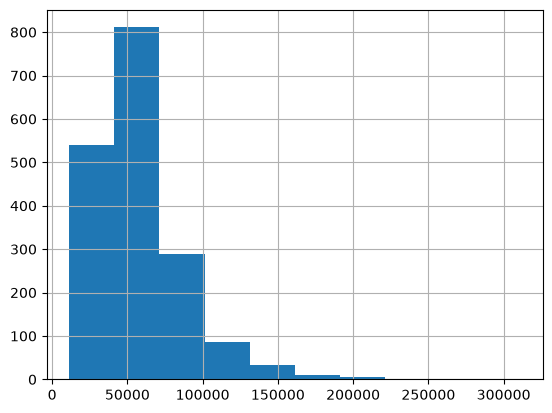

In [33]:
train_res['writing_time_no_pause'].hist()

In [34]:
for t in [30000, 50000, 70000, 100000]:
    subs = train_res[train_res['writing_time_no_pause'] < t]
    print(np.sqrt(mean_squared_error(subs['y_train'], subs['y_train_pred'])), len(subs) / len(train_res))

0.568869259640281 0.11023622047244094
0.5834814546160442 0.46737907761529807
0.6088447998608004 0.750843644544432
0.6249764002959146 0.9184476940382452


In [36]:
test_res = X_test.merge(y_test, left_index=True, right_index=True)
test_res ['y_test_pred'] = y_test_pred

In [37]:
test_res

,words_per_essay,events_per_essay,writing_duration,chars_per_essay,chars_per_minute,total_pauses,total_pause_time,perc_pause_time,pauses_per_words,removes_per_essay,...,perc_time_0.8,perc_time_0.9,words_no_pause,writing_time_no_pause,group,bursts_per_words,words_no_pause_per_words,writing_time_no_pause_per_time,score,y_test_pred
0,255,2557,1797443,2010,67.095313,124,1182600.0,0.657935,0.486275,417.0,...,0.651854,0.721284,12.0,23678.0,124,0.486275,0.047059,0.013173,3.5,3.249321
1,307,2353,1692754,1975,70.004265,56,1134643.0,0.670294,0.182410,222.0,...,0.308380,0.330437,67.0,85701.0,56,0.182410,0.218241,0.050628,4.0,3.472689
2,573,3721,1769301,3182,107.907021,126,748472.0,0.423033,0.219895,62.0,...,0.807460,0.927658,46.0,61310.0,127,0.221640,0.080279,0.034652,4.5,3.939070
3,234,2117,1748118,1690,58.005238,127,826154.0,0.472596,0.542735,108.0,...,0.691751,0.801612,19.0,40244.0,128,0.547009,0.081197,0.023021,2.5,3.013683
4,272,3446,1753635,2444,83.620594,132,799152.0,0.455712,0.485294,878.0,...,0.672317,0.779517,23.0,41775.0,133,0.488971,0.084559,0.023822,3.0,3.429543
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
490,228,1743,1779729,1543,52.019156,81,1383766.0,0.777515,0.355263,78.0,...,0.277126,0.305163,28.0,32971.0,81,0.355263,0.122807,0.018526,3.5,3.319284
491,410,2885,1722946,2636,91.796261,37,1201213.0,0.697186,0.090244,194.0,...,0.298639,0.326769,44.0,51727.0,37,0.090244,0.107317,0.030022,4.0,3.903719
492,247,2261,1784077,1613,54.246538,86,1099336.0,0.616193,0.348178,151.0,...,0.456226,0.488246,23.0,43844.0,86,0.348178,0.093117,0.024575,2.5,3.125695
493,480,4671,2058193,3351,97.687632,133,1075131.0,0.522366,0.277083,531.0,...,0.802553,0.936126,30.0,48991.0,134,0.279167,0.062500,0.023803,3.5,4.191317


In [41]:
for t in [30000, 50000, 70000, 100000]:
    subs = test_res[test_res['writing_time_no_pause'] < t]
    print(np.sqrt(mean_squared_error(subs['score'], subs['y_test_pred'])), len(subs) / len(test_res))

0.5843040791839857 0.11717171717171718
0.6324662974870989 0.4868686868686869
0.6740506313078024 0.7474747474747475
0.6841886186482747 0.898989898989899


<Axes: >

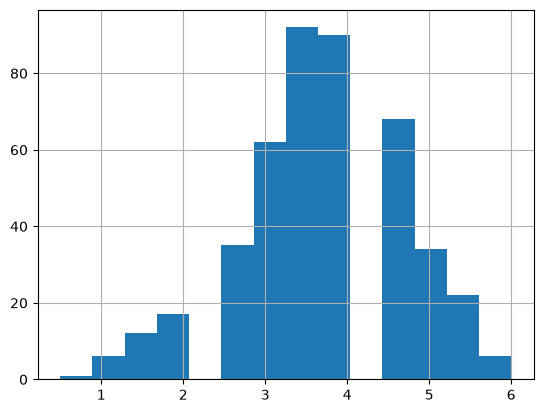

In [42]:
subs['score'].hist(bins=14)